# Projet Leyenda - Livrable 1
##### *Par Noah.V, Noah.M, Hugo.L*

## **Contexte:**
L'entreprise TouNum est une entreprise qui travaille sur la numérisation de différents type de documents. Ils essayent de moderniser leur architecture pour le tri automatique de documents due au grand nombre de documents fourni par les clients. Faisant appel à nous pour determiner le captionning des images avec légendes de manière automatiques. Nous remarquons deux contraintes, la première est la qualité des images qui diffère par exemple entre chaque image, et trié automatiquement si c'est une photo ou d'autres types de documents.

Le workflow demandé par l'entreprise devra suivre ce modèle la:

![Image demandé](src/workflow.png)

Le projet sera divisé en trois partie:
- La première sera de contrsuire un CNN via des datasets d'images pré étiqueté
- Le deuxième sera d'améliorer la clarté et l'enlever les différents bruits ou flou des images
- Le troisème sera de créer un réseau de neurones qui génère des légendes pour des photographies

Nous avons déjà réalisé le premier livrable avec différentes architectures, mais aussi différentes résolutions et comme on a pu le voir dans ce précédent livrable, les images redimensionné peuvent avoir du bruit ou être floue. C'est pour cela que dans ce ***deuxième livrable***, le but sera d'améliorer la clarté de ses images et permettre au modèle de mieux comprendre les images pour une meilleure detection.

Détail du ***Livrable 2:***
- Le code de chargement du fichier
- Le code du débruitage sur un sous-ensemble d'images bruitées. Le code doit être accompagné d'explications.
- Une étude de cas.

## Importation des librairies

In [3]:
%pip install -r requirements.txt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import regularizers
from sklearn.model_selection import train_test_split
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd
import plotly.express as px
from DL_dataset import *
from plotly.subplots import make_subplots
import plotly.graph_objects as go

Note: you may need to restart the kernel to use updated packages.


## Etape 1 : Chargement des images

Pour charger les differentes images de ce livrable 2, comme au livrable 1. Nous avons crée un script relier à *DL_datatset.py* qui a pour but de télécharger et préprocess les images automatiquements. Ensuite nous chargons les images dans les deux datasets train et test.

### Téléchargement du dataset

In [5]:
folder_raw = Path(f"./data")

if not os.path.exists(folder_raw):
    step_DL, step_unzip = True, True
    os.makedirs(folder_raw)
elif Path(folder_raw).exists() and len(os.listdir(folder_raw)) == 0:
    step_DL, step_unzip = True, True
else:
    step_DL, step_unzip = False, False

urls=[
    "https://drive.google.com/file/d/1Cp-x-Sc7wUzipu1GysZXx9g4Y2jrpIka/view?usp=sharing",
]

if step_DL==True:
    print("File download:")
    for link in urls:
        download_file(link,folder_raw)

if step_unzip==True:
    Get_file(folder_raw)

### Chargements des variables et Hyperparametres.

Ses différentes valeurs seront utilisés tout au long de ce notebook pour les models.

In [16]:
BATCH_SIZE = 32
IMG_SIZE = (128,128) 
train_split = 0.8
test_split = 0.2 

### Répartition des images

Due aux nombres limités d'images disponibles, nous décidons de partir sur une répartition 80/20.

In [17]:
dataset_raw = Path(f"./data/dataset/")

train_set = tf.keras.utils.image_dataset_from_directory(
    dataset_raw,
    validation_split=1 - train_split,
    labels=None,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    subset="training",
    seed=42
)

test_set = tf.keras.utils.image_dataset_from_directory(
    dataset_raw,
    validation_split=test_split,
    labels=None,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    subset="validation",
    seed=42
)

AUTOTUNE = tf.data.experimental.AUTOTUNE

normalization_layer = tf.keras.layers.Rescaling(1./255)

train_set = train_set.map(
    lambda x: (normalization_layer(x), normalization_layer(x))
)

test_set = test_set.map(
    lambda x: (normalization_layer(x), normalization_layer(x))
)

train_set = train_set.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
test_set = test_set.cache().prefetch(buffer_size=AUTOTUNE)

Found 148 files.
Using 119 files for training.
Found 148 files.
Using 29 files for validation.


### Affichage des images

Pour confirmer le chargement des images et que les images ont bien été séparé entre le *test set* et le *train set*.

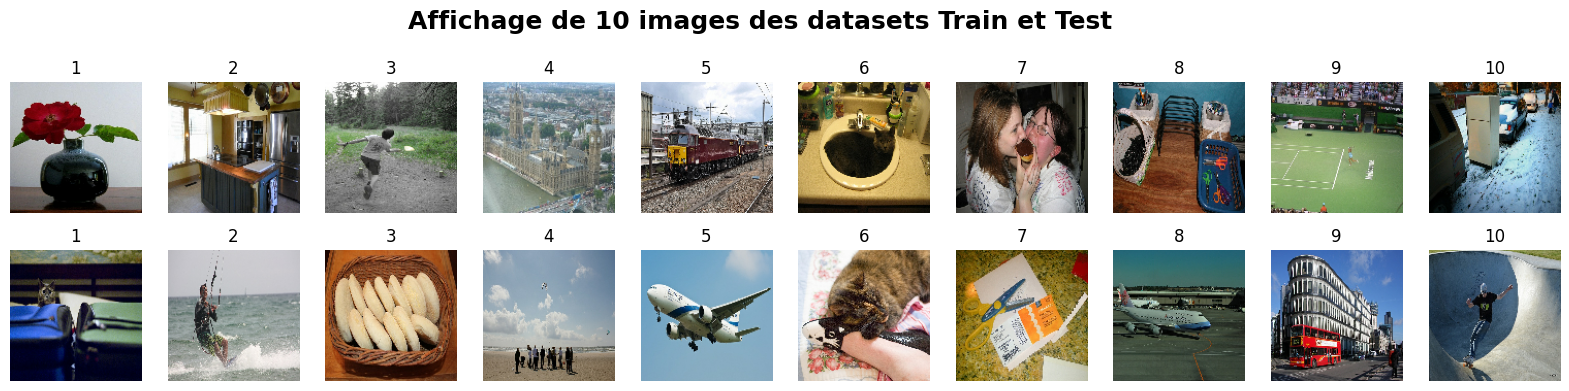

In [18]:
n = 10

#Affichage partie Trai,
plt.figure(figsize=(20, 4))
for images, _ in train_set.take(1):
    for i in range(n):
        ax = plt.subplot(2, n, i + 1)
        plt.imshow(images[i].numpy())
        plt.title(f'{i+1}')
        plt.axis("off")

#Affichage partie Test
for images, _ in test_set.take(1):
    for i in range(n):
        ax = plt.subplot(2, n, i + 1+n)
        plt.title("Image dans le set de Test")
        plt.imshow(images[i].numpy())
        plt.title(f'{i+1}')
        plt.axis("off") 

plt.suptitle("Affichage de 10 images des datasets Train et Test", fontsize=18, fontweight='bold', y=1.05)
plt.show() 

## Etape 2 : Code pour le débruitage

### Etude du modèle et des résultats

a completer

## Etape 3 : Etude de cas

### Comparaisson des différents modèles utilisés 

Pour ce projet, nous avons essayé d'utiliser plusieurs auto encoder differents, comme l'auto-encoder traditionnel, le VAE, le CAE, le DAE, CVAE...
Cependant plusieurs d'entre eux avaient des résultats qu'ils nous convenaient pas ou avaient des contraintes trop importantes pour être sélectionné. Comme l'auto encoder traditionnel qui...